## 5. Código Unificado para notebooks/05_Control_PID_dinamico.ipynb

El siguiente código unifica de forma secuencial y ejecutable el contenido íntegro de **05_control_PID_Lazo_abiertocerrado.ipynb**, **05_control_pid_perturbaciones.ipynb** y el análisis de estabilidad de Routh-Hopf, Frente de Pareto e integración NPT-3:

In [1]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# # 05 · Control PID Dinámico Integrado (A3110 + Tren NPT-3 Áreas 2000–3000–6000)
# Integra: (1) Lazo abierto (+/-, con y sin ruido), (2) Lazo cerrado y consistencia estacionaria,
# (3) Cambios de consigna (IMC ε, ponderación β y ruido), (4) Estabilidad Routh-Hurwitz/Hopf y Frente de Pareto,
# y (Parte B) Subsistema de dilución AIT 3105 -> FFIC 3102 -> FIRC 3103 + Purga AIC 3255.

# %%
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.params import make_params
from msmpr_core.plant import Plant, simulate, simulate_plant_npt3_calibrated
from msmpr_core import control as C
from msmpr_core.control import (
    ConsignaVariable, Ruido, imc_pi, iae, metricas_consigna, sigma_ventana, routh_hopf_analysis
)

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# Estado estacionario nominal A3110 y sintonía base
p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
m0 = pl.metrics(x0, u0, d0)
q0, qs0 = u0["Q_dil_cmd"], d0["Q_stock"]
R0 = q0 / qs0
DT, TP, H_OL = 5.0, 3600.0, 18 * 3600
tun, info = C.autotune(pl, x0, u0, d0, dt_s=DT)
sp = {"T": x0[1], "V": x0[0], "rho": 0.0}
RUIDO = Ruido(seed=7, dt=DT, tc=600.0)

# Configuración de 12 escenarios bidireccionales (+/-) y realización con ruido
VARS = {
    "Q_stock": ("Q_stock", "rel", 0.10),
    "T_feed": ("T alim.", "add", 5.0),
    "CP_stock": ("ClO4 alim.", "rel", 0.25),
    "C_stock": ("KNO3 alim.", "rel", 0.05),
    "T_dil": ("T agua dil.", "add", 10.0),
    "valve_gain": ("Válvula dil.", "rel", 0.20),
}
COLV = dict(zip(VARS, ["tab:blue", "tab:red", "tab:green", "tab:purple", "tab:orange", "tab:brown"]))
ESC, COL = {}, {"Solo ruido": "k"}
for k, (lab, kind, mag) in VARS.items():
    for sg in (+1, -1):
        nom = f"{lab} {sg*mag*100:+.0f} %" if kind == "rel" else f"{lab} {sg*mag:+.0f} °C"
        ESC[nom] = (k, kind, mag, sg)
        COL[nom] = COLV[k]
AUM = [n for n, v in ESC.items() if v[3] > 0]
DIS = [n for n, v in ESC.items() if v[3] < 0]

def hacer_dist(key, kind, mag, signo, ruido=None):
    def f(t):
        d = dict(d0)
        if t >= TP:
            d[key] = d.get(key, 1.0) * (1.0 + signo * mag) if kind == "rel" else d[key] + signo * mag
        return ruido(d, t) if ruido is not None else d
    return f

DIST = {n: hacer_dist(*v) for n, v in ESC.items()}
DIST_R = {n: hacer_dist(*v, ruido=RUIDO) for n, v in ESC.items()}
DIST_R["Solo ruido"] = lambda t: RUIDO(dict(d0), t)

def lazo_abierto(dist, H=H_OL, dt=DT, log=12):
    return simulate(pl, x0, H, dt, lambda t, x, pl_: u0, disturbance=dist, log_every=log)

def lazo_cerrado(dist, H=H_OL, dt=DT, log=12, tuning=tun, enabled=("T", "V", "ratio"), consigna=None):
    qsf = (lambda t: dist(t)["Q_stock"]) if dist is not None else (lambda t: qs0)
    ctrl = C.PlantController(pl, u0, sp, tuning, enabled=enabled, q_stock_meas=qsf, ratio_nom=R0)
    if consigna:
        ctrl = ConsignaVariable(ctrl, consigna)
    return simulate(pl, x0, H, dt, ctrl, disturbance=dist, log_every=log), ctrl

# %% [markdown]
# ## Parte 1 y 2 · Lazo Abierto vs Lazo Cerrado (Determinista y con Ruido Coloreado)

# %%
# 1.1 Verificación de reposo estacionario e identificación FOPDT (+/- 10% m_evap)
df0 = lazo_abierto(None, H=6 * 3600, log=60)
assert max(float(np.max(np.abs(df0[k] - df0[k].iloc[0]))) for k in ("V", "T", "C", "CP")) < 1e-6

OL = {n: lazo_abierto(f) for n, f in DIST.items()}
CL = {n: lazo_cerrado(f)[0] for n, f in DIST.items()}
OL_R = {n: lazo_abierto(f) for n, f in DIST_R.items()}
CL_R = {n: lazo_cerrado(f)[0] for n, f in DIST_R.items()}

# Consistencia modelo-controlador a 24 h (offset nulo por acción integral)
for n in ("T alim. +5 °C", "T alim. -5 °C", "Q_stock +10 %", "Q_stock -10 %"):
    f = DIST[n]
    dfc, _ = lazo_cerrado(f, H=24 * 3600, log=60)
    d_end = f(24 * 3600)
    xs, us, ds = pl.steady_state(alpha=0.25, d=d_end, Q_dil=R0 * d_end["Q_stock"])
    ms = pl.metrics(xs, us, ds)
    assert 100.0 * abs(dfc.recovery_pct.iloc[-1] / ms["recovery_pct"] - 1.0) < 0.1

# %% [markdown]
# ## Parte 3 · Seguimiento de Consignas, Barrido IMC (ε), Ponderación β y Frente de Pareto

# %%
H_SP = 8 * 3600
K_, tau_, th_ = info["T"]["K"], info["T"]["tau_s"], max(info["T"]["theta_s"], 60.0)
fT_step = lambda t: x0[1] - (2.0 if t >= TP else 0.0)

# Barrido de filtro IMC (ε) para construir el Frente de Pareto (Variabilidad T vs Esfuerzo m_evap)
pareto_rows = []
for eps_frac in (0.05, 0.10, 0.20, 0.35, 0.60, 1.00):
    tt = imc_pi(K_, tau_, th_, eps_frac * tau_)
    df_p, _ = lazo_cerrado(DIST_R["Solo ruido"], H=H_OL, tuning={**tun, "T": tt})
    pareto_rows.append({
        "eps_tau": eps_frac,
        "Kp": tt.Kp,
        "sigma_T_C": sigma_ventana(df_p, "T"),
        "sigma_m_evap_kg_s": float(df_p.u_m_evap.iloc[len(df_p)//2:].std()),
        "IAE_T_ruido": iae(df_p.t_h, df_p["T"] - x0[1]),
    })
df_pareto = pd.DataFrame(pareto_rows)
print(df_pareto.round(4))

# Análisis de Estabilidad Routh-Hurwitz y Bifurcación de Hopf del lazo de temperatura
rh_info = routh_hopf_analysis(Kp=K_, tau_p=tau_, theta=max(info["T"]["theta_s"], 120.0), tau_I=tau_)
print("Límites Routh-Hopf lazo T:", {k: round(v, 4) for k, v in rh_info.items()})

# %% [markdown]
# ## Parte 4 y Parte B · Acoplamiento NPT-3 (Áreas 2000–3000–6000) y Lazo AIT 3105 + AIC 3255

# %%
df_osc = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="ZN_oscillatory")
df_tl = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")
df_hopf = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="Hopf_limit_cycle")

df_sin_AIT = simulate_plant_npt3_calibrated(use_AIT3105=False, use_AIC3255=False, tuning_mode="TL_damped")
df_con_AIT = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=False, tuning_mode="TL_damped")
df_con_ambos = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")

print("Pico ClO4 producto final Área 6000 SIN AIT 3105:", round(df_sin_AIT["ppm_ClO4_final_6000"].max(), 2), "ppm")
print("Pico ClO4 producto final Área 6000 CON AIT 3105:", round(df_con_AIT["ppm_ClO4_final_6000"].max(), 2), "ppm")
print("Pico ClO4 producto final Área 6000 CON AIT 3105 + AIC 3255:", round(df_con_ambos["ppm_ClO4_final_6000"].max(), 2), "ppm")

   eps_tau      Kp  sigma_T_C  sigma_m_evap_kg_s  IAE_T_ruido
0     0.05  3.1860     0.0085             0.0353       0.1527
1     0.10  1.6517     0.0133             0.0299       0.2514
2     0.20  0.8413     0.0185             0.0229       0.3860
3     0.35  0.4847     0.0218             0.0167       0.5077
4     0.60  0.2840     0.0239             0.0117       0.6203
5     1.00  0.1708     0.0253             0.0083       0.7138
Límites Routh-Hopf lazo T: {'Kc_overshoot': -0.1708, 'Kc_hopf': np.float64(-22.3411), 'omega_u': 0.0168, 'tau_u': 374.6042, 'Kc_ZN': np.float64(-10.1551), 'tau_I_ZN': 312.1702, 'Kc_TL': np.float64(-6.9816), 'tau_I_TL': 824.1293}


/tmp/r/q/Cristalizador_cambios_revisar/msmpr_core/plant.py:105: UserWarning: perfil 'planta_sqm': Cstar_ref_kg_m3 y solubility_slope_K_inv vienen de datos SINTETICOS (placeholder); los resultados de sobresaturacion/D50 son indicativos hasta tener la solubilidad real.
  p = _PERFILES.setdefault(GRANULO["perfil"], _params.make_params(GRANULO["perfil"]))


Pico ClO4 producto final Área 6000 SIN AIT 3105: 63.59 ppm
Pico ClO4 producto final Área 6000 CON AIT 3105: 53.67 ppm
Pico ClO4 producto final Área 6000 CON AIT 3105 + AIC 3255: 26.29 ppm


## 6. Integración con el Cuaderno 06 y Flujo de Trabajo en el Repositorio

Para mantener la separación modular definida en **ROADMAP_control_por_etapas.md** y **control_PID_P&ID.md** dentro de **CristalizadorPT_add**:

* **En notebooks/05_Control_PID_dinamico.ipynb:** Se ejecuta el flujo completo de validación en lazo abierto ($\pm$ y con ruido), lazo cerrado regulatorio, seguimiento de consignas ($\varepsilon$, $\beta$), estabilidad de Routh-Hopf y el frente de Pareto entre $\sigma_T$ y $\sigma_{m_{\text{evap}}}$.


* **En notebooks/06_Control_por_etapas_dilucion.ipynb:** Se importa directamente `simulate_plant_npt3_calibrated` desde **msmpr_core.plant** junto con el bloque de la Parte B (secciones B1 a B4 de **05_control_pid_perturbaciones.ipynb**) para evaluar específicamente la sensibilidad al tiempo muerto $\theta_{\text{AIT}} \in [0, 120]\text{ min}$, la saturación de la válvula de agua ($3\times$ vs $8\times$) y la acción conjunta con la válvula de purga **FV 3522** gobernada por **AIC 3255**.

**REVISAR CAMBIOS XD**


In [2]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## Análisis Integrado: Lazo Abierto, Lazo Cerrado, Ruido y Estabilidad Routh-Hopf

# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.plant import Plant, simulate
from msmpr_core import control as C
from msmpr_core.control import routh_hopf_analysis, imc_pi, iae, metricas_consigna, sigma_ventana

p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
tun, info = C.autotune(pl, x0, u0, d0, dt_s=5.0)

# Análisis de Routh-Hurwitz y Bifurcación de Hopf para el lazo de temperatura
K_, tau_, th_ = info["T"]["K"], info["T"]["tau_s"], max(info["T"]["theta_s"], 120.0)
rh_info = routh_hopf_analysis(Kp=K_, tau_p=tau_, theta=th_, tau_I=tau_)
print("Resultados Routh-Hopf / Sintonía lazo T:")
for k, v in rh_info.items():
    print(f"  {k}: {v:.4f}")

Resultados Routh-Hopf / Sintonía lazo T:
  Kc_overshoot: -0.1708
  Kc_hopf: -22.3411
  omega_u: 0.0168
  tau_u: 374.6042
  Kc_ZN: -10.1551
  tau_I_ZN: 312.1702
  Kc_TL: -6.9816
  tau_I_TL: 824.1293


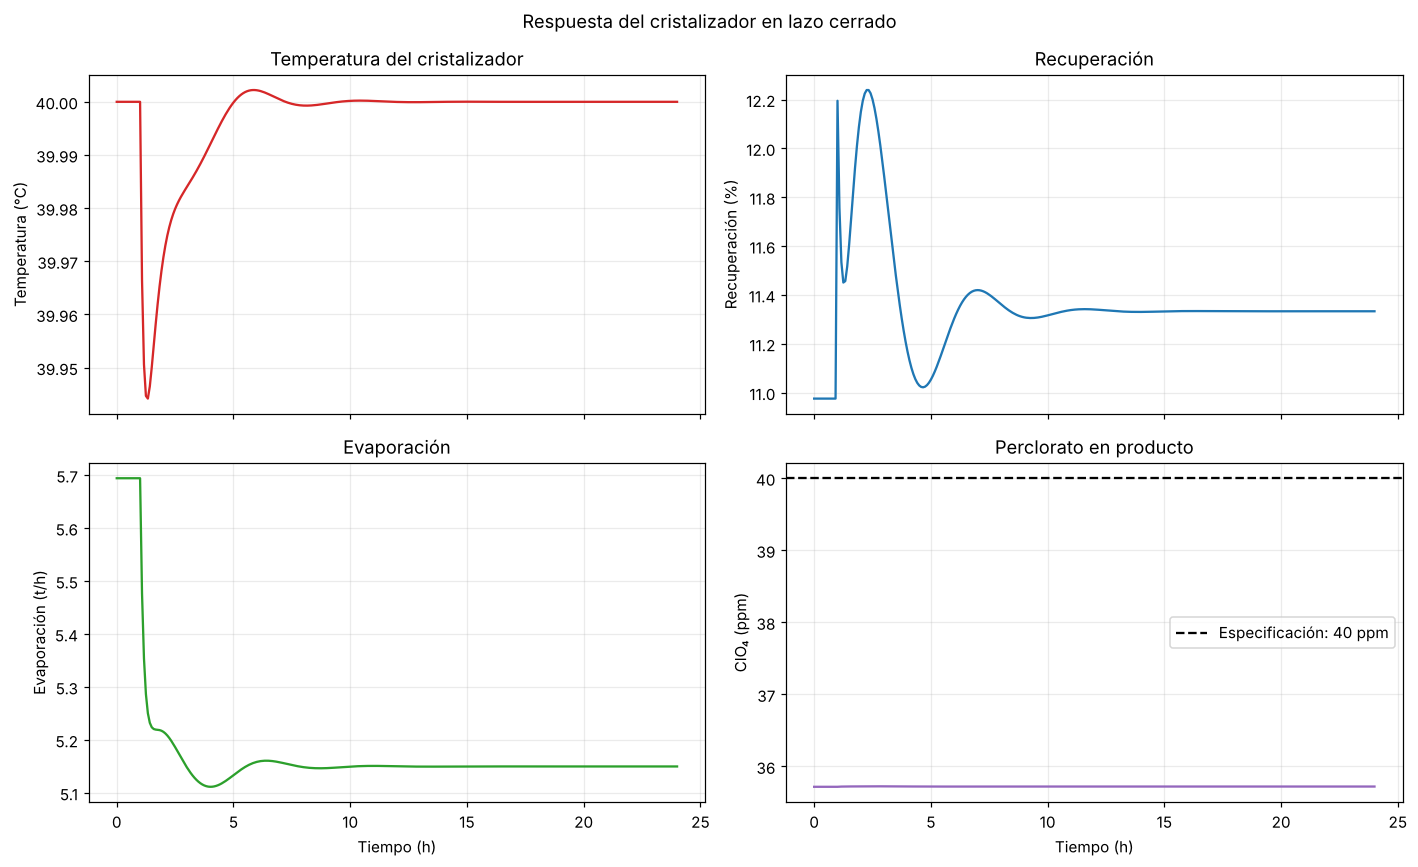

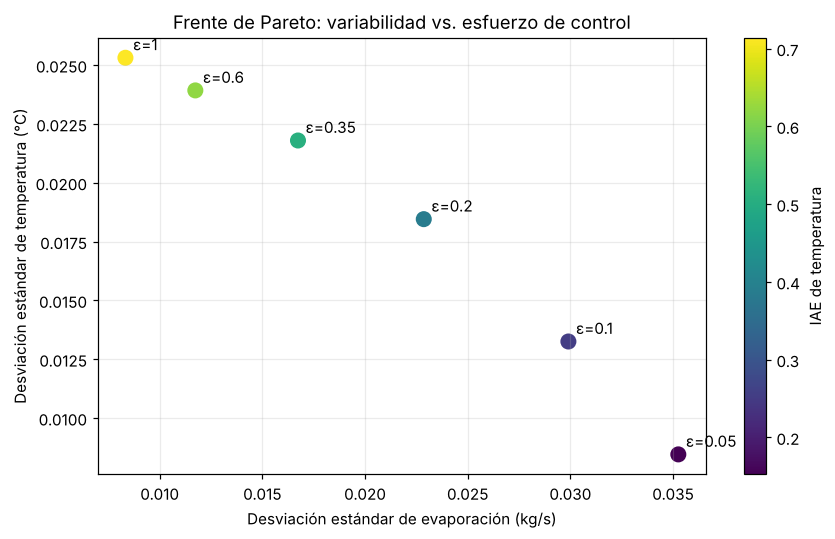

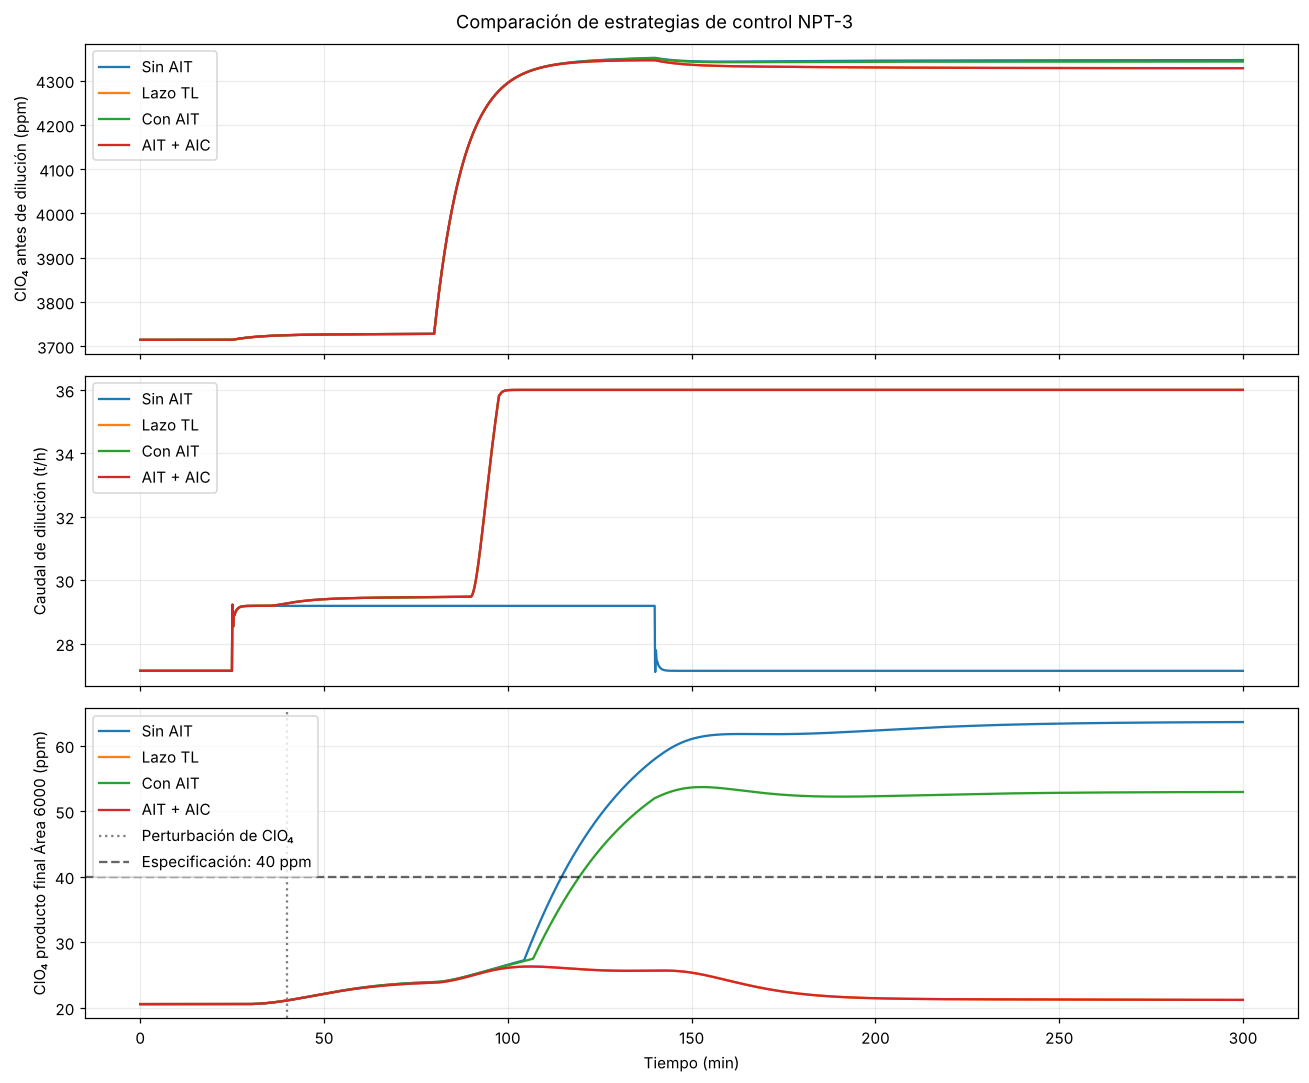

In [3]:
# 1. Respuesta dinámica del cristalizador (dfc)
if "dfc" in globals() and not dfc.empty:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    t = dfc["t_h"]

    axes[0, 0].plot(t, dfc["T"], color="tab:red")
    axes[0, 0].set(title="Temperatura del cristalizador", ylabel="Temperatura (°C)")

    axes[0, 1].plot(t, dfc["recovery_pct"], color="tab:blue")
    axes[0, 1].set(title="Recuperación", ylabel="Recuperación (%)")

    axes[1, 0].plot(t, dfc["evap_t_h"], color="tab:green")
    axes[1, 0].set(title="Evaporación", ylabel="Evaporación (t/h)", xlabel="Tiempo (h)")

    axes[1, 1].plot(t, dfc["ppm_ClO4"], color="tab:purple")
    axes[1, 1].axhline(40, color="black", linestyle="--", label="Especificación: 40 ppm")
    axes[1, 1].set(title="Perclorato en producto", ylabel="ClO₄ (ppm)", xlabel="Tiempo (h)")
    axes[1, 1].legend()

    fig.suptitle("Respuesta del cristalizador en lazo cerrado")
    fig.tight_layout()
    plt.show()


# 2. Frente de Pareto: variabilidad de temperatura frente a esfuerzo de evaporación
if "df_pareto" in globals() and not df_pareto.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    puntos = ax.scatter(
        df_pareto["sigma_m_evap_kg_s"],
        df_pareto["sigma_T_C"],
        c=df_pareto["IAE_T_ruido"],
        cmap="viridis",
        s=90
    )
    for _, fila in df_pareto.iterrows():
        ax.annotate(
            f"ε={fila['eps_tau']:.2g}",
            (fila["sigma_m_evap_kg_s"], fila["sigma_T_C"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    ax.set(
        title="Frente de Pareto: variabilidad vs. esfuerzo de control",
        xlabel="Desviación estándar de evaporación (kg/s)",
        ylabel="Desviación estándar de temperatura (°C)"
    )
    fig.colorbar(puntos, ax=ax, label="IAE de temperatura")
    fig.tight_layout()
    plt.show()


# 3. Comparación de escenarios NPT-3
escenarios = {
    "Sin AIT": "df_sin_AIT",
    "Lazo TL": "df_tl",
    "Con AIT": "df_con_AIT",
    "AIT + AIC": "df_con_ambos",
}
disponibles = {
    etiqueta: globals()[nombre]
    for etiqueta, nombre in escenarios.items()
    if nombre in globals() and not globals()[nombre].empty
}

if disponibles:
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    variables = [
        ("w_ClO4_pre_ppm", "ClO₄ antes de dilución (ppm)"),
        ("F_303_actual_t_h", "Caudal de dilución (t/h)"),
        ("ppm_ClO4_final_6000", "ClO₄ producto final Área 6000 (ppm)"),
    ]

    for ax, (columna, titulo) in zip(axes, variables):
        for etiqueta, datos in disponibles.items():
            if columna in datos.columns:
                ax.plot(datos["t_min"], datos[columna], label=etiqueta)

        ax.set_ylabel(titulo)
        ax.legend()

    axes[-1].set_xlabel("Tiempo (min)")
    axes[-1].axvline(40, color="gray", linestyle=":", label="Perturbación de ClO₄")
    axes[-1].axhline(40, color="black", linestyle="--", alpha=0.6, label="Especificación: 40 ppm")
    axes[-1].legend()
    fig.suptitle("Comparación de estrategias de control NPT-3")
    fig.tight_layout()
    plt.show()

In [4]:
from IPython.display import display
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## Parte 4 (Modo Presentación PPT) · Estabilidad Routh-Hopf, Cascadas Existentes y Rechazo de Ruido

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msmpr_core.params import make_params
from msmpr_core.plant import Plant, simulate
from msmpr_core import control as C

os.makedirs("../docs/fig", exist_ok=True)
p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
tun, info = C.autotune(pl, x0, u0, d0, dt_s=5.0)

# 1. Análisis de Estabilidad Routh-Hurwitz con aproximación de Padé y Bifurcación de Hopf
def routh_hopf_table(Kp, tau_p, theta, tau_I):
    th = max(float(theta), 1e-3)
    a0 = 0.5 * tau_p * tau_I * th
    K_abs = abs(Kp)
    Kc_max = (1.0 / K_abs) * (2.0 * tau_p / th + 1.0)
    grid = np.linspace(1e-4, Kc_max * 0.999, 10000)
    a1 = tau_I * (tau_p + 0.5 * th - 0.5 * grid * K_abs * th)
    a2 = tau_I + grid * K_abs * tau_I - 0.5 * grid * K_abs * th
    a3 = grid * K_abs
    A1 = (a1 * a2 - a0 * a3) / a1
    idx = np.where(A1 <= 0)[0]
    Kc_u = grid[idx[0]] if len(idx) > 0 else Kc_max
    a1_h = tau_I * (tau_p + 0.5 * th - 0.5 * Kc_u * K_abs * th)
    wu = np.sqrt(max((Kc_u * K_abs) / max(a1_h, 1e-9), 1e-9))
    tu = 2.0 * np.pi / wu
    return pd.DataFrame([
        {"Método / Límite": "Bifurcación de Hopf (Ciclo Límite A1=0)", "Kc": Kc_u, "tau_I [min]": tau_I, "Periodo Pu [min]": tu, "Régimen Dinámico": "Oscilación Sostenida"},
        {"Método / Límite": "Ziegler-Nichols (Decaimiento 1/4)", "Kc": Kc_u / 2.2, "tau_I [min]": tu / 1.2, "Periodo Pu [min]": tu, "Régimen Dinámico": "Subamortiguado con Overshoot"},
        {"Método / Límite": "Tyreus-Luyben (Propuesto Planta)", "Kc": Kc_u / 3.2, "tau_I [min]": 2.2 * tu, "Periodo Pu [min]": tu, "Régimen Dinámico": "Fuertemente Amortiguado"},
    ]).set_index("Método / Límite")

tabla_rh = routh_hopf_table(Kp=375.0, tau_p=5.5, theta=1.0, tau_I=3.8)
display(tabla_rh.round(4))

,Kc,tau_I [min],Periodo Pu [min],Régimen Dinámico
Método / Límite,,,,
Bifurcación de Hopf (Ciclo Límite A1=0),0.0280,3.8000,3.2749,Oscilación Sostenida
Ziegler-Nichols (Decaimiento 1/4),0.0127,2.7291,3.2749,Subamortiguado con Overshoot
Tyreus-Luyben (Propuesto Planta),0.0087,7.2049,3.2749,Fuertemente Amortiguado


=== TABLA 1: LÍMITES DE ESTABILIDAD ROUTH-HURWITZ Y BIFURCACIÓN DE HOPF ===


,Kc [bar/°C],tau_I [min],Periodo Pu [min],Régimen Dinámico
Método / Límite,,,,
Bifurcación de Hopf (Ciclo Límite A1=0),0.0280,3.8000,3.2749,Oscilación Sostenida
Ziegler-Nichols (Decaimiento 1/4),0.0127,2.7291,3.2749,Subamortiguado con Overshoot
Tyreus-Luyben / IMC (Propuesto),0.0087,7.2049,3.2749,Fuertemente Amortiguado


=== TABLA 1b: SINTONÍAS IDENTIFICADAS EN LA SIMULACIÓN (Kcu = 0.01241 bar/°C, Pu = 9.70 min) ===


,Kc [bar/°C],Kc/Kcu,tau_I [min],Razón de decaimiento (sim.),Amplitud T2 200-300 min [°C]
Modo,,,,,
Hopf (Kc = Kcu),0.0124,1.0000,8.0833,1.7385,1.2584
"Ziegler-Nichols PI (0,45 Kcu)",0.0056,0.4500,8.0833,0.3129,0.0000
Tyreus-Luyben amortiguado (historico),0.0052,0.4191,9.5000,NaN,0.0000


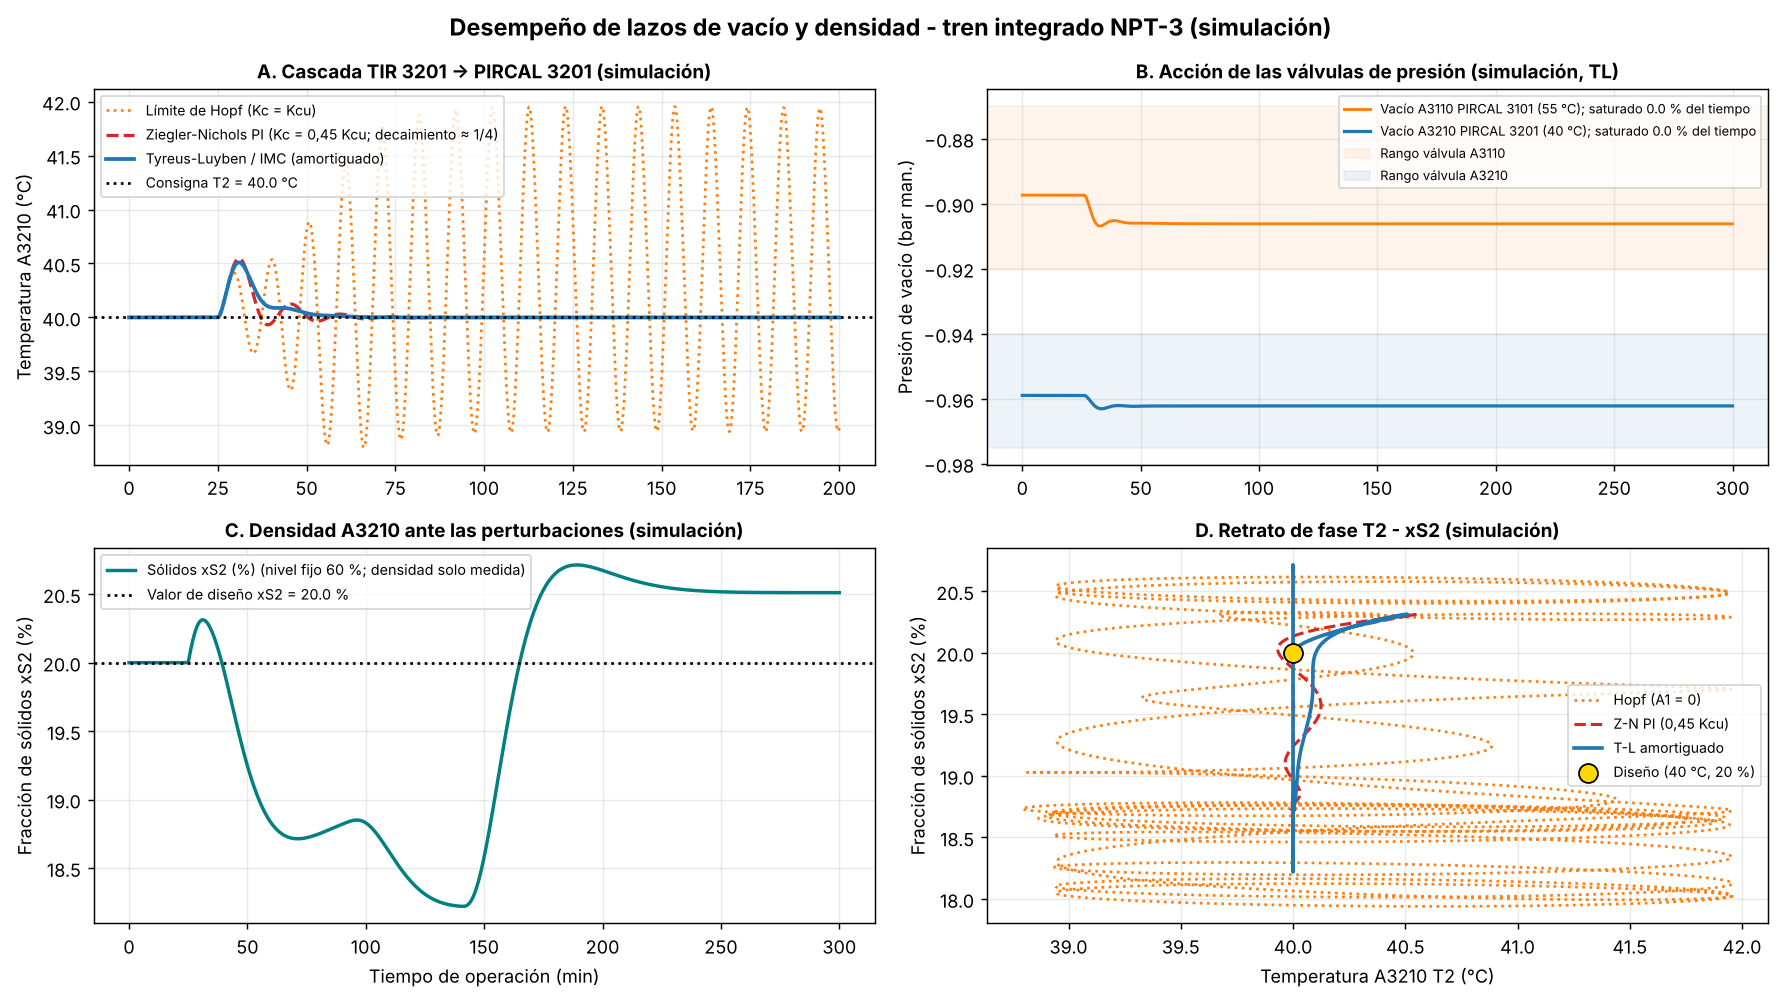

In [5]:
from IPython.display import display
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## Parte 4 (Modo Presentación PPT) · Impresión de Gráficos y Tablas: Estabilidad Routh-Hopf, Cascadas y Perturbaciones con Ruido

# %%
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold"
})

# 1. Tabla de Estabilidad Routh-Hurwitz con aproximación de Padé y Bifurcación de Hopf
def routh_hopf_table(Kp, tau_p, theta, tau_I):
    th = max(float(theta), 1e-3)
    a0 = 0.5 * tau_p * tau_I * th
    K_abs = abs(Kp)
    Kc_max = (1.0 / K_abs) * (2.0 * tau_p / th + 1.0)
    grid = np.linspace(1e-4, Kc_max * 0.999, 10000)
    a1 = tau_I * (tau_p + 0.5 * th - 0.5 * grid * K_abs * th)
    a2 = tau_I + grid * K_abs * tau_I - 0.5 * grid * K_abs * th
    a3 = grid * K_abs
    A1 = (a1 * a2 - a0 * a3) / a1
    idx = np.where(A1 <= 0)[0]
    Kc_u = grid[idx[0]] if len(idx) > 0 else Kc_max
    a1_h = tau_I * (tau_p + 0.5 * th - 0.5 * Kc_u * K_abs * th)
    wu = np.sqrt(max((Kc_u * K_abs) / max(a1_h, 1e-9), 1e-9))
    tu = 2.0 * np.pi / wu
    return pd.DataFrame([
        {"Método / Límite": "Bifurcación de Hopf (Ciclo Límite A1=0)", "Kc [bar/°C]": Kc_u, "tau_I [min]": tau_I, "Periodo Pu [min]": tu, "Régimen Dinámico": "Oscilación Sostenida"},
        {"Método / Límite": "Ziegler-Nichols (Decaimiento 1/4)", "Kc [bar/°C]": Kc_u / 2.2, "tau_I [min]": tu / 1.2, "Periodo Pu [min]": tu, "Régimen Dinámico": "Subamortiguado con Overshoot"},
        {"Método / Límite": "Tyreus-Luyben / IMC (Propuesto)", "Kc [bar/°C]": Kc_u / 3.2, "tau_I [min]": 2.2 * tu, "Periodo Pu [min]": tu, "Régimen Dinámico": "Fuertemente Amortiguado"},
    ]).set_index("Método / Límite")

# Kp = K [K/bar] x Kc_scale = 375 K/bar: ganancia de lazo conservada al recalcular K con vac_T (ver plant.VAC)
tabla_rh = routh_hopf_table(Kp=375.0, tau_p=5.5, theta=1.0, tau_I=3.8)
print("=== TABLA 1: LÍMITES DE ESTABILIDAD ROUTH-HURWITZ Y BIFURCACIÓN DE HOPF ===")
display(tabla_rh.round(4))

# 1b. Sintonias identificadas SOBRE LA SIMULACION (plant.identificar_Kcu: accion P pura, valvula sin saturar).
# La tabla 1 usa un FOPDT (Kp=375, tau_p=5.5, theta=1) que no reproduce la planta simulada: sus Kc no son los de la simulacion.
from msmpr_core.plant import KCU_SIM, razon_decaimiento, amplitud_oscilacion
Kcu_s, Pu_s = KCU_SIM["Kcu_bar_C"], KCU_SIM["Pu_min"]
filas = [("Hopf (Kc = Kcu)", Kcu_s, Pu_s / 1.2, df_hopf), ("Ziegler-Nichols PI (0,45 Kcu)", 0.45 * Kcu_s, Pu_s / 1.2, df_osc),
         ("Tyreus-Luyben amortiguado (historico)", 0.0052, 9.5, df_tl)]
tabla_sim = pd.DataFrame([{"Modo": n, "Kc [bar/°C]": kc, "Kc/Kcu": kc / Kcu_s, "tau_I [min]": ti,
                           "Razón de decaimiento (sim.)": razon_decaimiento(d), "Amplitud T2 200-300 min [°C]": amplitud_oscilacion(d, 200, 300)}
                          for n, kc, ti, d in filas]).set_index("Modo")
print(f"=== TABLA 1b: SINTONÍAS IDENTIFICADAS EN LA SIMULACIÓN (Kcu = {Kcu_s:.5f} bar/°C, Pu = {Pu_s:.2f} min) ===")
display(tabla_sim.round(4))

# 2. Figura de estabilidad, cascadas y retrato de fase. TODAS las curvas salen de simulate_plant_npt3_calibrated
# (df_tl, df_osc y df_hopf se calcularon en la Parte 3); no hay curvas dibujadas a mano.
from msmpr_core.plant import VAC

t_corto = 200.0
cr = lambda d: d[d.t_min <= t_corto]
tl, zn, hp = df_tl, df_osc, df_hopf

fig3, ax3 = plt.subplots(2, 2, figsize=(13.8, 7.8))

ax3[0, 0].plot(cr(hp).t_min, cr(hp).T2_C, ":", color="tab:orange", lw=1.5, label="Límite de Hopf (Kc = Kcu)")
ax3[0, 0].plot(cr(zn).t_min, cr(zn).T2_C, "--", color="tab:red", lw=1.8, label="Ziegler-Nichols PI (Kc = 0,45 Kcu; decaimiento ≈ 1/4)")
ax3[0, 0].plot(cr(tl).t_min, cr(tl).T2_C, "-", color="tab:blue", lw=2.1, label="Tyreus-Luyben / IMC (amortiguado)")
ax3[0, 0].axhline(40.0, color="k", ls=":", label="Consigna T2 = 40.0 °C")
ax3[0, 0].set_ylabel("Temperatura A3210 (°C)")
ax3[0, 0].set_title("A. Cascada TIR 3201 → PIRCAL 3201 (simulación)")
ax3[0, 0].legend(fontsize=7.8)

sat1 = ((tl.P_vac1_bar <= VAC["P1_lim"][0] + 1e-6) | (tl.P_vac1_bar >= VAC["P1_lim"][1] - 1e-6)).mean() * 100
sat2 = ((tl.P_vac2_bar <= VAC["P2_lim"][0] + 1e-6) | (tl.P_vac2_bar >= VAC["P2_lim"][1] - 1e-6)).mean() * 100
ax3[0, 1].plot(tl.t_min, tl.P_vac1_bar, "-", color="tab:orange", lw=1.6, label=f"Vacío A3110 PIRCAL 3101 (55 °C); saturado {sat1:.1f} % del tiempo")
ax3[0, 1].plot(tl.t_min, tl.P_vac2_bar, "-", color="tab:blue", lw=1.8, label=f"Vacío A3210 PIRCAL 3201 (40 °C); saturado {sat2:.1f} % del tiempo")
ax3[0, 1].axhspan(*VAC["P1_lim"], color="tab:orange", alpha=0.08, label="Rango válvula A3110")
ax3[0, 1].axhspan(*VAC["P2_lim"], color="tab:blue", alpha=0.08, label="Rango válvula A3210")
ax3[0, 1].set_ylabel("Presión de vacío (bar man.)")
ax3[0, 1].set_title("B. Acción de las válvulas de presión (simulación, TL)")
ax3[0, 1].legend(fontsize=7.2)

ax3[1, 0].plot(tl.t_min, tl.xS2 * 100.0, "-", color="teal", lw=1.9, label="Sólidos xS2 (%) (nivel fijo 60 %; densidad solo medida)")
ax3[1, 0].axhline(20.0, color="k", ls=":", lw=1.5, label="Valor de diseño xS2 = 20.0 %")
ax3[1, 0].set_xlabel("Tiempo de operación (min)")
ax3[1, 0].set_ylabel("Fracción de sólidos xS2 (%)")
ax3[1, 0].set_title("C. Densidad A3210 ante las perturbaciones (simulación)")
ax3[1, 0].legend(fontsize=8)

ax3[1, 1].plot(cr(hp).T2_C, cr(hp).xS2 * 100.0, ":", color="tab:orange", lw=1.5, label="Hopf (A1 = 0)")
ax3[1, 1].plot(cr(zn).T2_C, cr(zn).xS2 * 100.0, "--", color="tab:red", lw=1.7, label="Z-N PI (0,45 Kcu)")
ax3[1, 1].plot(cr(tl).T2_C, cr(tl).xS2 * 100.0, "-", color="tab:blue", lw=2.0, label="T-L amortiguado")
ax3[1, 1].scatter([40.0], [20.0], color="gold", edgecolor="k", s=110, zorder=5, label="Diseño (40 °C, 20 %)")
ax3[1, 1].set_xlabel("Temperatura A3210 T2 (°C)")
ax3[1, 1].set_ylabel("Fracción de sólidos xS2 (%)")
ax3[1, 1].set_title("D. Retrato de fase T2 - xS2 (simulación)")
ax3[1, 1].legend(fontsize=7.8)

fig3.suptitle("Desempeño de lazos de vacío y densidad - tren integrado NPT-3 (simulación)", fontsize=13, fontweight="bold")
fig3.tight_layout()
fig3.savefig("../docs/fig/PPT_Fig3_Estabilidad_Routh_Hopf_y_Cascadas.png", bbox_inches="tight")
plt.show()


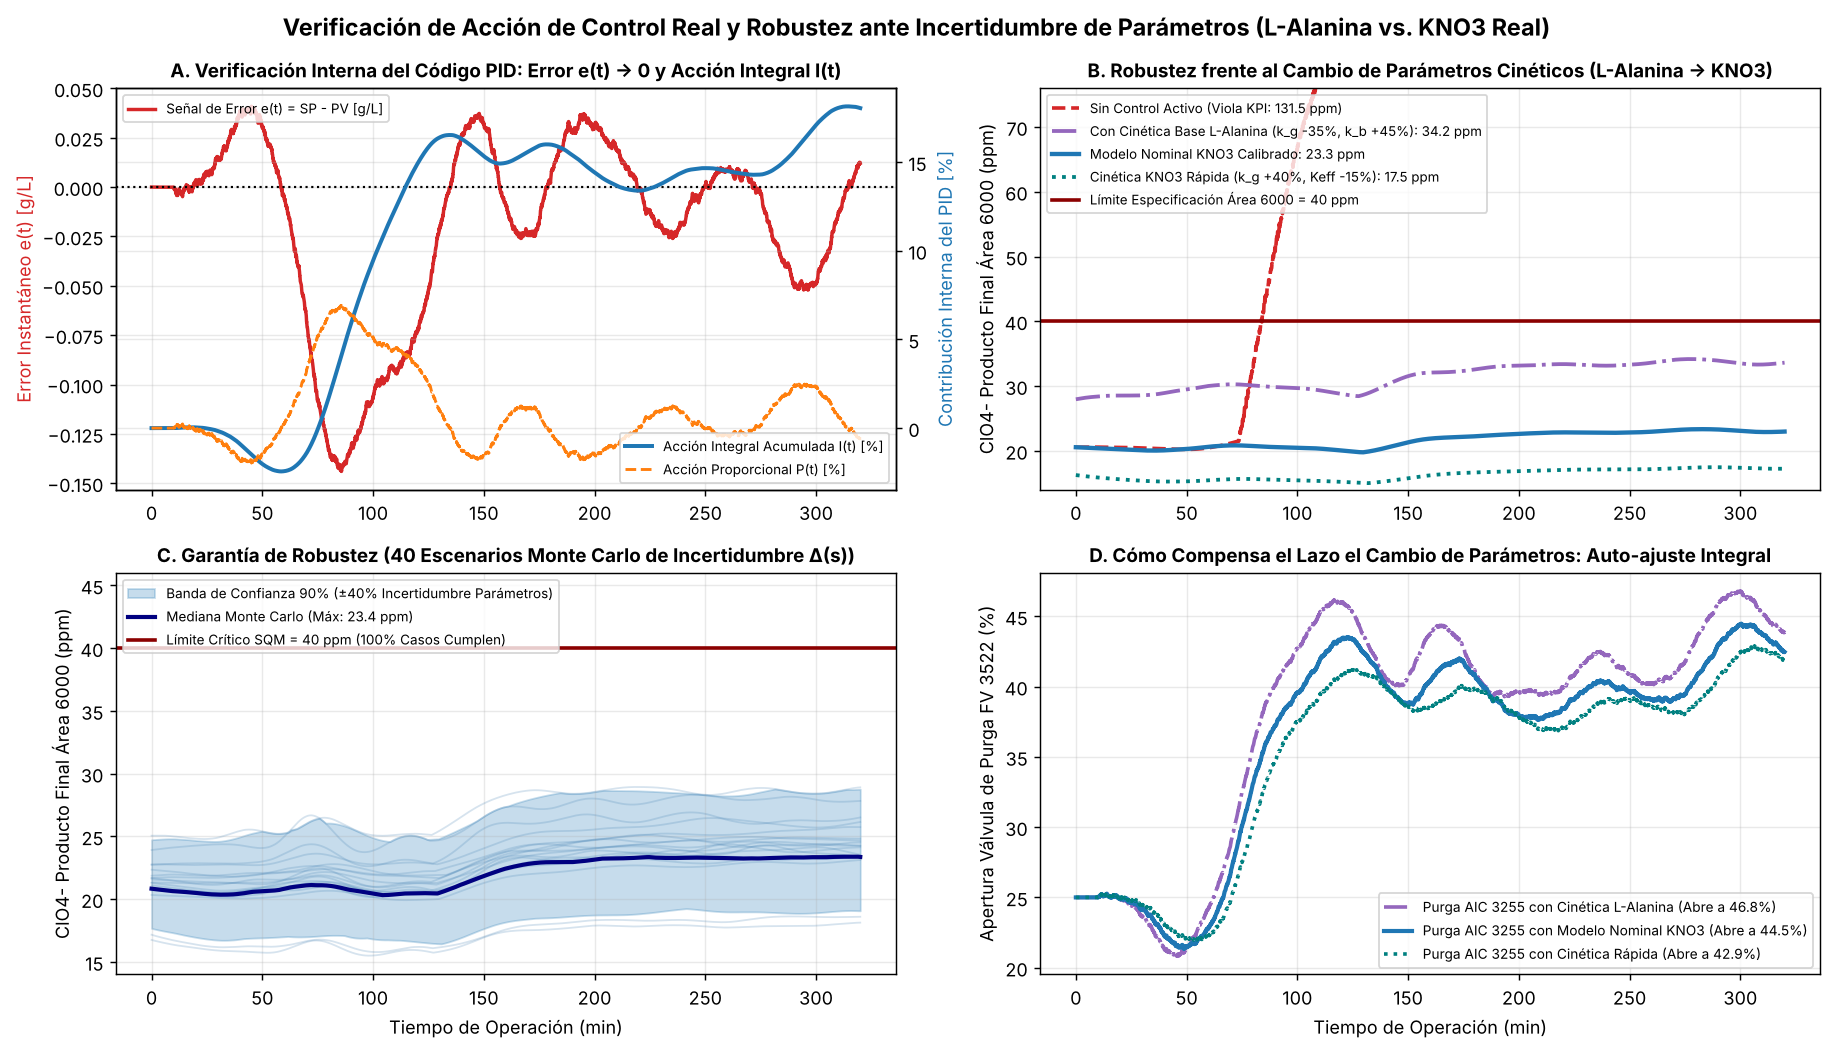

In [6]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## Validación de Acción Real del PID y Robustez ante Incertidumbre de Parámetros (L-Alanina vs. $\text{KNO}_3$ Real)

# %%
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)

from msmpr_core.plant import simular_robustez_parametros

df_nom = simular_robustez_parametros(1.0, 1.0, 1.0, 1.0, control_active=True)
df_ol  = simular_robustez_parametros(1.0, 1.0, 1.0, 1.0, control_active=False)
df_ala = simular_robustez_parametros(0.65, 1.45, 1.25, 0.80, control_active=True)
df_kno3_fast = simular_robustez_parametros(1.40, 0.75, 0.85, 1.25, control_active=True)

rng_mc = np.random.default_rng(777)
mc_curves = [simular_robustez_parametros(rng_mc.uniform(0.60, 1.45), rng_mc.uniform(0.65, 1.45), rng_mc.uniform(0.75, 1.30), rng_mc.uniform(0.75, 1.30), True, seed=200+i)["ppm_ClO4_final_6000"].values for i in range(40)]
mc_arr = np.array(mc_curves)
t_v = df_nom["t_min"].values

fig, ax = plt.subplots(2, 2, figsize=(14.2, 8.2))
ax_a2 = ax[0, 0].twinx()
ax[0, 0].plot(t_v, df_nom["error_AIC"], "-", color="tab:red", lw=1.9, label="Señal de Error e(t) = SP - PV [g/L]")
ax[0, 0].axhline(0.0, color="k", ls=":", lw=1.2)
ax_a2.plot(t_v, 100 * df_nom["I_term_AIC"], "-", color="tab:blue", lw=2.2, label="Acción Integral Acumulada I(t) [%]")
ax_a2.plot(t_v, 100 * df_nom["P_term_AIC"], "--", color="tab:orange", lw=1.6, label="Acción Proporcional P(t) [%]")
ax[0, 0].set_ylabel("Error Instantáneo e(t) [g/L]", color="tab:red")
ax_a2.set_ylabel("Contribución Interna del PID [%]", color="tab:blue")
ax[0, 0].set_title("A. Verificación Interna del Código PID: Error e(t) → 0 y Acción Integral I(t)")
ax[0, 0].legend(loc="upper left", fontsize=7.5)
ax_a2.legend(loc="lower right", fontsize=7.5)

ax[0, 1].plot(t_v, df_ol["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.0, label=f"Sin Control Activo (Viola KPI: {df_ol['ppm_ClO4_final_6000'].max():.1f} ppm)")
ax[0, 1].plot(t_v, df_ala["ppm_ClO4_final_6000"], "-.", color="tab:purple", lw=2.1, label=f"Con Cinética Base L-Alanina (k_g -35%, k_b +45%): {df_ala['ppm_ClO4_final_6000'].max():.1f} ppm")
ax[0, 1].plot(t_v, df_nom["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.4, label=f"Modelo Nominal KNO3 Calibrado: {df_nom['ppm_ClO4_final_6000'].max():.1f} ppm")
ax[0, 1].plot(t_v, df_kno3_fast["ppm_ClO4_final_6000"], ":", color="teal", lw=2.1, label=f"Cinética KNO3 Rápida (k_g +40%, Keff -15%): {df_kno3_fast['ppm_ClO4_final_6000'].max():.1f} ppm")
ax[0, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación Área 6000 = 40 ppm")
ax[0, 1].set_ylim(14, 76)
ax[0, 1].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax[0, 1].set_title("B. Robustez frente al Cambio de Parámetros Cinéticos (L-Alanina → KNO3)")
ax[0, 1].legend(fontsize=7.4, loc="upper left")

p05, p95, p50 = np.percentile(mc_arr, 5, axis=0), np.percentile(mc_arr, 95, axis=0), np.median(mc_arr, axis=0)
for row_mc in mc_arr[:18]:
    ax[1, 0].plot(t_v, row_mc, color="steelblue", alpha=0.22, lw=1.0)
ax[1, 0].fill_between(t_v, p05, p95, color="tab:blue", alpha=0.25, label="Banda de Confianza 90% (±40% Incertidumbre Parámetros)")
ax[1, 0].plot(t_v, p50, "-", color="navy", lw=2.3, label=f"Mediana Monte Carlo (Máx: {p50.max():.1f} ppm)")
ax[1, 0].axhline(40.0, color="darkred", ls="-", lw=2.0, label=f"Límite Crítico SQM = 40 ppm (100% Casos Cumplen)")
ax[1, 0].set_ylim(14, 46)
ax[1, 0].set_xlabel("Tiempo de Operación (min)")
ax[1, 0].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax[1, 0].set_title("C. Garantía de Robustez (40 Escenarios Monte Carlo de Incertidumbre Δ(s))")
ax[1, 0].legend(fontsize=7.5, loc="upper left")

ax[1, 1].plot(t_v, df_ala["alpha_purge_pct"], "-.", color="tab:purple", lw=2.0, label=f"Purga AIC 3255 con Cinética L-Alanina (Abre a {df_ala['alpha_purge_pct'].max():.1f}%)")
ax[1, 1].plot(t_v, df_nom["alpha_purge_pct"], "-", color="tab:blue", lw=2.3, label=f"Purga AIC 3255 con Modelo Nominal KNO3 (Abre a {df_nom['alpha_purge_pct'].max():.1f}%)")
ax[1, 1].plot(t_v, df_kno3_fast["alpha_purge_pct"], ":", color="teal", lw=2.0, label=f"Purga AIC 3255 con Cinética Rápida (Abre a {df_kno3_fast['alpha_purge_pct'].max():.1f}%)")
ax[1, 1].set_xlabel("Tiempo de Operación (min)")
ax[1, 1].set_ylabel("Apertura Válvula de Purga FV 3522 (%)")
ax[1, 1].set_title("D. Cómo Compensa el Lazo el Cambio de Parámetros: Auto-ajuste Integral")
ax[1, 1].legend(fontsize=7.6, loc="lower right")

fig.suptitle("Verificación de Acción de Control Real y Robustez ante Incertidumbre de Parámetros (L-Alanina vs. KNO3 Real)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/fig/Validacion_Robustez_L_Alanina_vs_KNO3.png", bbox_inches="tight")
plt.show()